# Extrayendo contenido de PUCP
### [Pagina de cursos](https://educacioncontinua.pucp.edu.pe/tipo-de-actividad/cursos/)
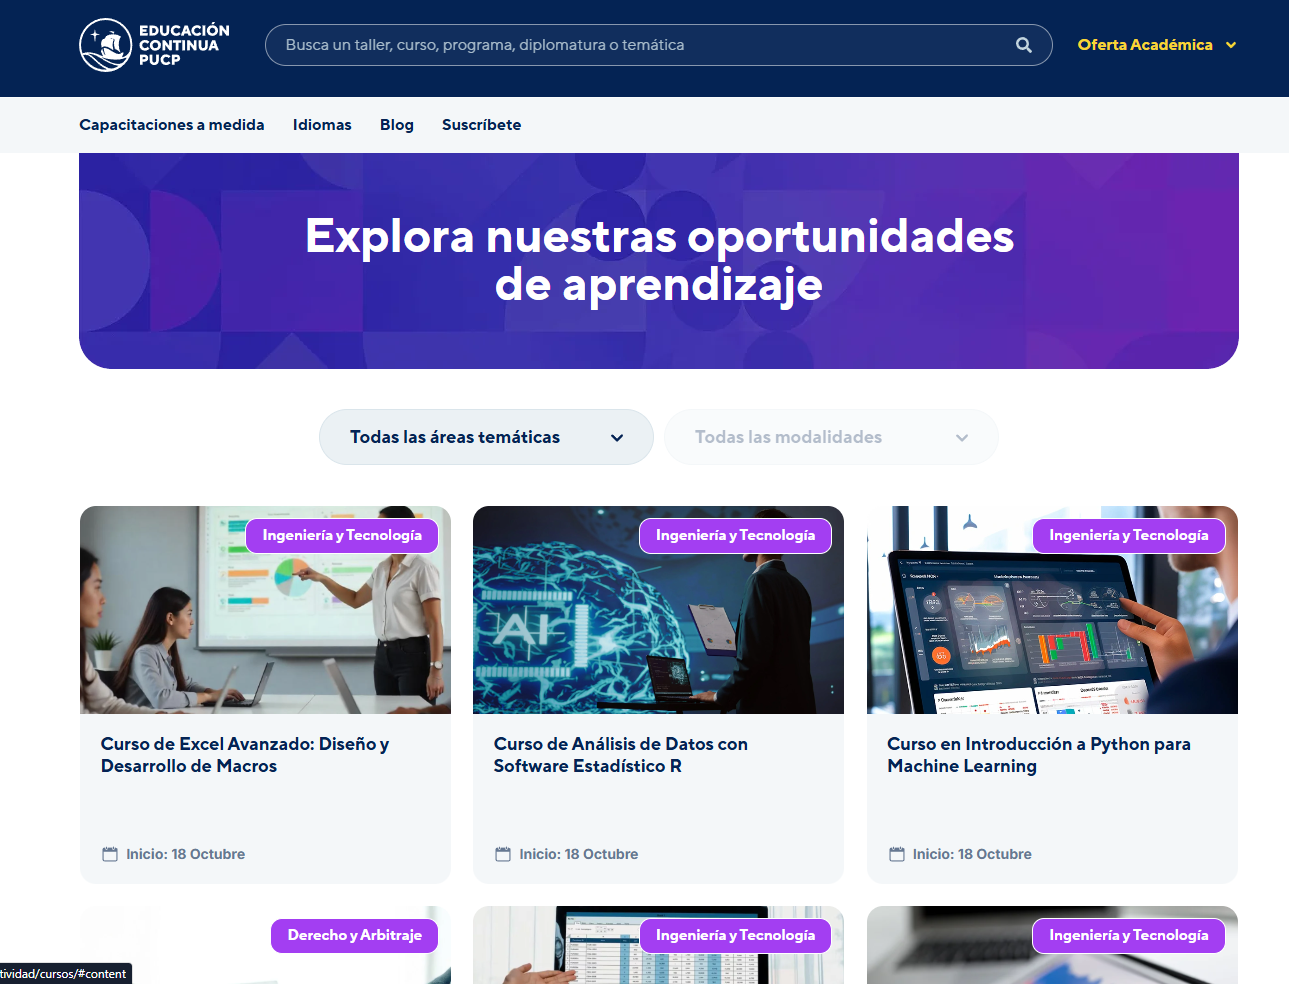


In [28]:
#  Librerias
import requests
import pandas as pd
from bs4 import BeautifulSoup
from urllib.parse import urljoin
import time


# 2. CONFIGURAR LA URL PRINCIPAL Y LA SESIÓN

BASE_URL = "https://educacioncontinua.pucp.edu.pe/tipo-de-actividad/cursos/"

# Crear una sesión para realizar las solicitudes HTTP
session = requests.Session()

# Identificarnos como un navegador
session.headers.update({
    "User-Agent": "Mozilla/5.0"
})


# 3. DESCARGAR LA PRIMERA PÁGINA

response = session.get(BASE_URL, timeout=30)

# Comprobar que la solicitud fue exitosa
response.raise_for_status()

# Convertir el HTML en un objeto BeautifulSoup
soup = BeautifulSoup(response.text, "html.parser")


# 4. DETECTAR EL NÚMERO TOTAL DE PÁGINAS

# Buscar el contenedor que informa cuántas páginas existen
grid = soup.select_one(
    ".jet-listing-grid__items[data-pages]"
)

# Obtener el total de páginas; usar 1 si no se encuentra
total_paginas = (
    int(grid.get("data-pages", 1))
    if grid else 1
)

print(f"Total de páginas detectadas: {total_paginas}")


# 5. PREPARAR LA LISTA DONDE GUARDAREMOS LOS RESULTADOS

resultados = []


# 6. RECORRER TODAS LAS PÁGINAS

for pagina in range(1, total_paginas + 1):

    # Construir la URL de cada página
    if pagina == 1:
        url_pagina = BASE_URL
        pagina_soup = soup
    else:
        url_pagina = (
            f"{BASE_URL}jsf/jet-engine/pagenum/{pagina}/"
        )

        # Descargar el HTML de la página actual
        try:
            r = session.get(url_pagina, timeout=30)
            r.raise_for_status()

            pagina_soup = BeautifulSoup(
                r.text, "html.parser"
            )

        except requests.RequestException as e:
            print(f"Error en la página {pagina}: {e}")
            continue

    print(f"\nProcesando página {pagina}/{total_paginas}")

    # 7. BUSCAR LAS TARJETAS DE LOS CURSOS

    tarjetas = pagina_soup.select(
        ".jet-listing-grid__item"
    )

    cursos_pagina = 0

    # Recorrer cada tarjeta encontrada
    for tarjeta in tarjetas:

        # Buscar el contenedor que contiene la URL del curso
        overlay = tarjeta.select_one(
            ".jet-engine-listing-overlay-wrap[data-url]"
        )

        if not overlay:
            continue

        # Extraer la URL del curso
        url = overlay.get("data-url", "").strip()

        # Excluir enlaces que no correspondan a cursos
        if "/cursos/" not in url:
            continue

        if "/tipo-de-actividad/" in url:
            continue

        # 8. EXTRAER LA CATEGORÍA

        # La categoría aparece en el primer campo dinámico
        # de la tarjeta, fuera del contenedor con clase "titul"
        campo_categoria = overlay.select_one(
            ".elementor-element-0cb3372 "
            ".jet-listing-dynamic-field__content"
        )

        categoria = (
            campo_categoria.get_text(" ", strip=True)
            if campo_categoria else None
        )

        # 9. EXTRAER EL NOMBRE REAL DEL CURSO

        # El título se encuentra dentro de la clase "titul"
        campo_curso = overlay.select_one(
            ".titul .jet-listing-dynamic-field__content"
        )

        curso = (
            campo_curso.get_text(" ", strip=True)
            if campo_curso else None
        )

        # 10. GUARDAR CATEGORÍA, CURSO Y URL

        if curso and url:

            resultados.append({
                "categoria": categoria,
                "curso": curso,
                "url": urljoin(url_pagina, url)
            })

            cursos_pagina += 1

    # Mostrar cuántos cursos se encontraron en esta página
    print(f"Cursos encontrados: {cursos_pagina}")

    # Esperar un segundo antes de consultar la siguiente página
    if pagina < total_paginas:
        time.sleep(1) # Es para que no detecten que estas scrapeando


# 11. CREAR EL DATAFRAME FINAL

# Crear el DataFrame con el orden de columnas solicitado
df_cursos = pd.DataFrame(
    resultados,
    columns=["categoria", "curso", "url"]
)

# Eliminar posibles cursos duplicados por su URL
df_cursos = df_cursos.drop_duplicates(
    subset=["url"]
).reset_index(drop=True)


# 12. MOSTRAR LOS RESULTADOS

display(df_cursos)

# Mostrar el total de cursos únicos
print(f"\nTotal de cursos únicos: {len(df_cursos)}")


# 13. GUARDAR EL RESULTADO EN EXCEL Y CSV

try:
    # Exportar a Excel
    df_cursos.to_excel(
        "../Data_temporal/cursos_pucp.xlsx",
        index=False
    )

    # Exportar a CSV compatible con Excel
    df_cursos.to_csv(
        "../Data_temporal/cursos_pucp.csv",
        index=False,
        encoding="utf-8-sig"
    )

    print("Archivos Excel y CSV exportados correctamente.")

except Exception as e:
    print(f"Error al exportar los archivos: {e}")

print("\nArchivos guardados correctamente.")

Total de páginas detectadas: 8

Procesando página 1/8
Cursos encontrados: 12

Procesando página 2/8
Cursos encontrados: 12

Procesando página 3/8
Cursos encontrados: 12

Procesando página 4/8
Cursos encontrados: 12

Procesando página 5/8
Cursos encontrados: 12

Procesando página 6/8
Cursos encontrados: 12

Procesando página 7/8
Cursos encontrados: 12

Procesando página 8/8
Cursos encontrados: 6


,categoria,curso,url
0,Ingeniería y Tecnología,Curso de Excel Avanzado: Diseño y Desarrollo d...,https://educacioncontinua.pucp.edu.pe/cursos/e...
1,Ingeniería y Tecnología,Curso de Análisis de Datos con Software Estadí...,https://educacioncontinua.pucp.edu.pe/cursos/a...
2,Ingeniería y Tecnología,Curso en Introducción a Python para Machine Le...,https://educacioncontinua.pucp.edu.pe/cursos/i...
3,Derecho y Arbitraje,Curso en Diseño de Fideicomisos y Titulización...,https://educacioncontinua.pucp.edu.pe/cursos/d...
4,Ingeniería y Tecnología,Taller en Presupuestos y Control Presupuestal ...,https://educacioncontinua.pucp.edu.pe/cursos/p...
...,...,...,...
77,Gestión 4.0,Curso de Branding Estratégico,https://educacioncontinua.pucp.edu.pe/cursos/b...
78,IA para el Mundo,Curso de Inteligencia Artificial Aplicada a la...,https://educacioncontinua.pucp.edu.pe/cursos/i...
79,Gestión Comercial,Curso de Key Account Management: Liderazgo y G...,https://educacioncontinua.pucp.edu.pe/cursos/k...
80,Ingeniería y Tecnología,Curso de Power BI Business Intelligence Primer...,https://educacioncontinua.pucp.edu.pe/cursos/p...



Total de cursos únicos: 82
Archivos Excel y CSV exportados correctamente.

Archivos guardados correctamente.


In [29]:
df_cursos

,categoria,curso,url
0,Ingeniería y Tecnología,Curso de Excel Avanzado: Diseño y Desarrollo d...,https://educacioncontinua.pucp.edu.pe/cursos/e...
1,Ingeniería y Tecnología,Curso de Análisis de Datos con Software Estadí...,https://educacioncontinua.pucp.edu.pe/cursos/a...
2,Ingeniería y Tecnología,Curso en Introducción a Python para Machine Le...,https://educacioncontinua.pucp.edu.pe/cursos/i...
3,Derecho y Arbitraje,Curso en Diseño de Fideicomisos y Titulización...,https://educacioncontinua.pucp.edu.pe/cursos/d...
4,Ingeniería y Tecnología,Taller en Presupuestos y Control Presupuestal ...,https://educacioncontinua.pucp.edu.pe/cursos/p...
...,...,...,...
77,Gestión 4.0,Curso de Branding Estratégico,https://educacioncontinua.pucp.edu.pe/cursos/b...
78,IA para el Mundo,Curso de Inteligencia Artificial Aplicada a la...,https://educacioncontinua.pucp.edu.pe/cursos/i...
79,Gestión Comercial,Curso de Key Account Management: Liderazgo y G...,https://educacioncontinua.pucp.edu.pe/cursos/k...
80,Ingeniería y Tecnología,Curso de Power BI Business Intelligence Primer...,https://educacioncontinua.pucp.edu.pe/cursos/p...


In [15]:
elemento = soup.select_one('[data-url*="/cursos/"]')

if elemento:
    print(elemento.prettify()[:6000])
else:
    print("No se encontraron elementos con data-url de cursos.")

<div class="jet-engine-listing-overlay-wrap" data-url="https://educacioncontinua.pucp.edu.pe/tipo-de-actividad/cursos/">
 <div class="elementor elementor-16523" data-elementor-id="16523" data-elementor-post-type="jet-engine" data-elementor-type="jet-listing-items">
  <div class="elementor-element elementor-element-781f8cf e-flex e-con-boxed e-con e-parent" data-e-type="container" data-element_type="container" data-id="781f8cf">
   <div class="e-con-inner">
    <div class="elementor-element elementor-element-06c6f3b e-con-full e-flex e-con e-child" data-e-type="container" data-element_type="container" data-id="06c6f3b">
     <div class="elementor-element elementor-element-a47bd5b e-con-full e-flex e-con e-child" data-e-type="container" data-element_type="container" data-id="a47bd5b">
      <div class="elementor-element elementor-element-423a0dc elementor-widget elementor-widget-jet-listing-dynamic-image" data-e-type="widget" data-element_type="widget" data-id="423a0dc" data-widget_type=

In [19]:
tarjeta = soup.select_one(
    '.jet-listing-grid__item [data-url*="/cursos/"]'
)

if tarjeta:
    print(tarjeta.parent.prettify()[:12000])

<div class="jet-listing-grid__item jet-listing-dynamic-post-27677 elementor-dcss-8671823588374977" data-post-id="27677">
 <div class="jet-engine-listing-overlay-wrap" data-url="https://educacioncontinua.pucp.edu.pe/cursos/excel-avanzado-diseno-desarrollo-macros-3/">
  <div class="elementor elementor-1430" data-elementor-id="1430" data-elementor-post-type="jet-engine" data-elementor-type="jet-listing-items">
   <div class="elementor-element elementor-element-70ff106 e-flex e-con-boxed e-con e-parent" data-e-type="container" data-element_type="container" data-id="70ff106">
    <div class="e-con-inner">
     <div class="elementor-element elementor-element-676c2e4 e-con-full prog-cont e-flex e-con e-child" data-e-type="container" data-element_type="container" data-id="676c2e4">
      <div class="elementor-element elementor-element-7c73f6d e-con-full e-flex e-con e-child" data-e-type="container" data-element_type="container" data-id="7c73f6d">
       <div class="elementor-element elementor-

In [20]:
for tarjeta in soup.select(".jet-listing-grid__item"):
    overlay = tarjeta.select_one(
        '.jet-engine-listing-overlay-wrap[data-url*="/cursos/"]'
    )

    if overlay:
        url = overlay.get("data-url", "")

        if "/tipo-de-actividad/" not in url:
            print("URL:", url)
            print(overlay.get_text(" ", strip=True))
            print(overlay.prettify()[:10000])
            break

URL: https://educacioncontinua.pucp.edu.pe/cursos/excel-avanzado-diseno-desarrollo-macros-3/
Ingeniería y Tecnología Curso de Excel Avanzado: Diseño y Desarrollo de Macros Inicio: 18 octubre
<div class="jet-engine-listing-overlay-wrap" data-url="https://educacioncontinua.pucp.edu.pe/cursos/excel-avanzado-diseno-desarrollo-macros-3/">
 <div class="elementor elementor-1430" data-elementor-id="1430" data-elementor-post-type="jet-engine" data-elementor-type="jet-listing-items">
  <div class="elementor-element elementor-element-70ff106 e-flex e-con-boxed e-con e-parent" data-e-type="container" data-element_type="container" data-id="70ff106">
   <div class="e-con-inner">
    <div class="elementor-element elementor-element-676c2e4 e-con-full prog-cont e-flex e-con e-child" data-e-type="container" data-element_type="container" data-id="676c2e4">
     <div class="elementor-element elementor-element-7c73f6d e-con-full e-flex e-con e-child" data-e-type="container" data-element_type="container" da